In [11]:
%pip install qiskit qiskit-aer matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [12]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
import pandas as pd
import math
from IPython.display import display, Markdown

simulator = AerSimulator()

## 1. Create a Single-Qubit Quantum Circuit

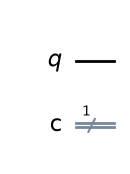

In [6]:
from qiskit import QuantumCircuit
display(Markdown("## 1. Create a Single-Qubit Quantum Circuit"))

# Create a circuit with exactly 1 qubit and 1 classical bit
qc = QuantumCircuit(1, 1)

# Display the circuit
display(qc.draw(output="mpl"))

## 2. Initial State: |0>

Initial qubit state: |0>
Number of qubits: 1


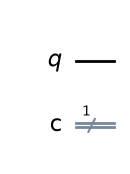

In [7]:
# The qubit is already initialized to |0>
display(Markdown("## 2. Initial State: |0>"))

print("Initial qubit state: |0>")
print("Number of qubits:", qc.num_qubits)

# Display the initial circuit
display(qc.draw(output="mpl"))

In [9]:
from IPython.display import display, Markdown

display(Markdown("""
## Prediction Before Execution

**1. Will 0 or 1 occur more frequently?**

Outcome 0 is expected to occur more frequently.

**2. Approximately what percentage of measurements will produce each outcome?**

For an Ry(π/3) gate:
- Outcome 0: approximately 75%
- Outcome 1: approximately 25%

For 100 shots, I expect approximately 75 zeros and 25 ones.

**3. What happens if you change the gates in your circuit?**

Changing the quantum gates or the rotation angle changes the qubit's
state and its measurement probabilities. For example:
- Ry(π/3): 0 is more likely (75%).
- Ry(π/2): both outcomes are equally likely (50% each).
- Ry(2π/3): 1 is more likely (75%).

The actual counts may vary slightly because the circuit is executed
for only 100 shots.
"""))


## Prediction Before Execution

**1. Will 0 or 1 occur more frequently?**

Outcome 0 is expected to occur more frequently.

**2. Approximately what percentage of measurements will produce each outcome?**

For an Ry(π/3) gate:
- Outcome 0: approximately 75%
- Outcome 1: approximately 25%

For 100 shots, I expect approximately 75 zeros and 25 ones.

**3. What happens if you change the gates in your circuit?**

Changing the quantum gates or the rotation angle changes the qubit's
state and its measurement probabilities. For example:
- Ry(π/3): 0 is more likely (75%).
- Ry(π/2): both outcomes are equally likely (50% each).
- Ry(2π/3): 1 is more likely (75%).

The actual counts may vary slightly because the circuit is executed
for only 100 shots.


## 3. Biased Quantum Circuit

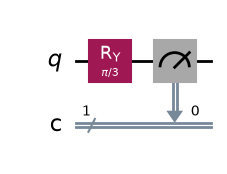

Number of qubits: 1
Quantum gates before measurement: 1


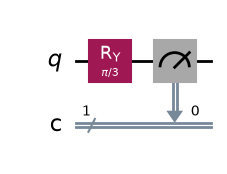

In [17]:
display(Markdown("## 3. Biased Quantum Circuit"))

biased_circuit = QuantumCircuit(1, 1)

biased_circuit.ry(math.pi / 3, 0)
biased_circuit.measure(0, 0)

display(biased_circuit.draw(output="mpl"))

print("Number of qubits:", biased_circuit.num_qubits)
print("Quantum gates before measurement: 1")

In [18]:
display(Markdown("## 4. Execute the Circuit for 100 Shots"))

job = simulator.run(biased_circuit, shots=100)
result = job.result()
counts = result.get_counts()

print("Measurement results:", counts)
print("Total shots:", sum(counts.values()))

## 4. Execute the Circuit for 100 Shots

Measurement results: {'0': 76, '1': 24}
Total shots: 100


In [19]:
display(Markdown("## 5. Measurement Results"))

zeros = counts.get("0", 0)
ones = counts.get("1", 0)

results_table = pd.DataFrame({
    "Outcome": ["0", "1"],
    "Count": [zeros, ones],
    "Actual Percentage": [zeros, ones]
})

results_table["Actual Percentage"] = (
    results_table["Actual Percentage"] / 100 * 100
)

display(results_table)

## 5. Measurement Results

,Outcome,Count,Actual Percentage
0,0,76,76.0
1,1,24,24.0


## 6. Histogram of Measurement Results

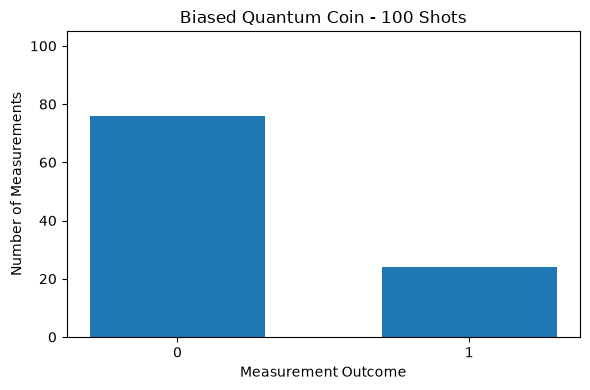

In [20]:
display(Markdown("## 6. Histogram of Measurement Results"))

plt.figure(figsize=(6, 4))
plt.bar(
    ["0", "1"],
    [zeros, ones],
    width=0.6
)

plt.title("Biased Quantum Coin - 100 Shots")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Measurements")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

In [21]:
display(Markdown("## 7. Different Degrees of Bias"))

angles = {
    "Ry(pi/3)": math.pi / 3,
    "Ry(pi/2)": math.pi / 2,
    "Ry(2pi/3)": 2 * math.pi / 3
}

bias_results = {}

for name, angle in angles.items():
    circuit = QuantumCircuit(1, 1)
    circuit.ry(angle, 0)
    circuit.measure(0, 0)

    print(f"\n{name}")
    print("Predicted P(0):", round(math.cos(angle / 2) ** 2 * 100, 2), "%")
    print("Predicted P(1):", round(math.sin(angle / 2) ** 2 * 100, 2), "%")

    result = simulator.run(circuit, shots=100).result()
    bias_results[name] = result.get_counts()

    print("Actual counts:", bias_results[name])

## 7. Different Degrees of Bias


Ry(pi/3)
Predicted P(0): 75.0 %
Predicted P(1): 25.0 %
Actual counts: {'0': 80, '1': 20}

Ry(pi/2)
Predicted P(0): 50.0 %
Predicted P(1): 50.0 %
Actual counts: {'1': 46, '0': 54}

Ry(2pi/3)
Predicted P(0): 25.0 %
Predicted P(1): 75.0 %
Actual counts: {'1': 71, '0': 29}


## 8. Bonus: Compare Two Biased Circuits

Circuit where 0 is more frequent: {'0': 76, '1': 24}
Circuit where 1 is more frequent: {'1': 79, '0': 21}


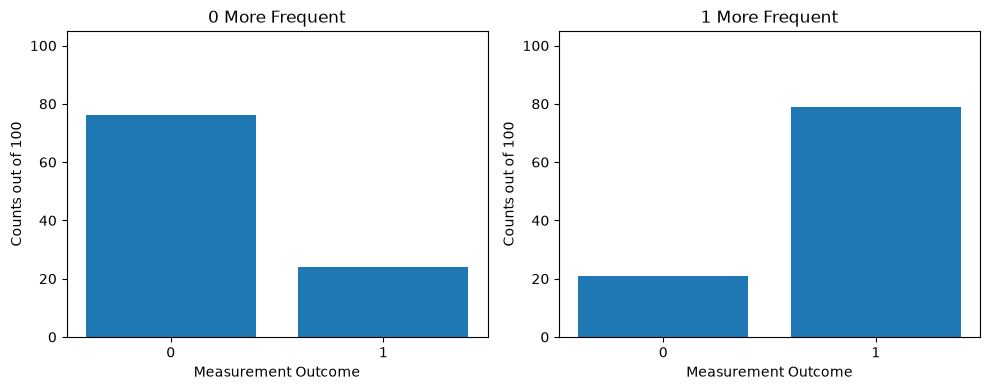

In [22]:
display(Markdown("## 8. Bonus: Compare Two Biased Circuits"))

circuit_zero = QuantumCircuit(1, 1)
circuit_zero.ry(math.pi / 3, 0)
circuit_zero.measure(0, 0)

circuit_one = QuantumCircuit(1, 1)
circuit_one.ry(2 * math.pi / 3, 0)
circuit_one.measure(0, 0)

bonus_counts_zero = simulator.run(
    circuit_zero, shots=100
).result().get_counts()

bonus_counts_one = simulator.run(
    circuit_one, shots=100
).result().get_counts()

print("Circuit where 0 is more frequent:", bonus_counts_zero)
print("Circuit where 1 is more frequent:", bonus_counts_one)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, measurement_counts in [
    (axes[0], "0 More Frequent", bonus_counts_zero),
    (axes[1], "1 More Frequent", bonus_counts_one)
]:
    ax.bar(
        ["0", "1"],
        [
            measurement_counts.get("0", 0),
            measurement_counts.get("1", 0)
        ]
    )
    ax.set_title(name)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Counts out of 100")
    ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

In [ ]:
## A Short Explaination of How your gates changed the Measurement Distribution  

The qubit initially starts in state |0⟩. I applied an R_y rotation gate to create unequal measurement probabilities. With an angle of π/3, the predicted probability of measuring 0 is 75%, while the probability of measuring 1 is 25%.

The circuit was executed for 100 shots, and the measurement counts were recorded and displayed in a histogram. Changing the rotation angle changes the probability amplitudes and therefore changes the measurement distribution. An angle of π/2 produces approximately equal probabilities, while an angle of 2π/3 makes outcome 1 more likely than outcome 0.

The actual counts may differ slightly from the predicted percentages because the simulation uses a finite number of shots.

In [ ]:
## Challenge Question

**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

Quantum gates change the quantum state and probability amplitudes of a qubit. When the qubit is measured, the probabilities of obtaining 0 or 1 are determined by the squared magnitudes of the corresponding amplitudes. By applying different gates or changing a rotation angle, we can control these probabilities and create a fair or biased quantum coin.